## Color-magnitude diagram from interpolated BaSTI isochrones
***IN PROGRESS\
Esther Kwon\
Massimo Ricotti\
Department of Astronomy, University of Maryland\
Last Updated: 5/26/26

***

BaSTI isochrones provide stellar models for the absolute magnitude of stars measured through different photometric systems\
Photometric system of interest is JWST NIRcam Sirio ZP (or annotated as isc_jwst-nircam_zp_vega-sirius)

To obtain a color magnitude diagram given a cluster age, mass, lookback time/redshift, and filters of interest;\
a mass distribution, K-corrections, and AB magnitude corrections must be applied to the BaSTI isochrone to represent a \
real cluster at some distance of some age and metallicity

In [ ]:
#pip install --user -r requirementsgc.txt

#### Import Statements

In [1]:
import numpy as np
import pandas as pd
import os
from imf import imf
import io
import ipywidgets as widgets
from ipyfilechooser import FileChooser
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt
from astropy import coordinates as coord
from astropy import units as u
from astropy.modeling import models
from astropy.table import Table
from astropy.io import fits

#### Docking Isochrone Bank
Select folder with all isochrones from BaSTI: http://basti-iac.oa-abruzzo.inaf.it/isocs.html 

In [2]:
#open folder selection UI (currently I am importing "NIRCAM Sirio ZP_zpS_Isochrones_SolarScaled")
fc = FileChooser('.')
display(fc)

FileChooser(path='C:\Users\Esther\Globular cluster project', filename='', title='', show_hidden=False, select_…

In [3]:
#set selected folder as directory and iterate through isochrone files
folder = Path(fc.selected_path)
files = list(folder.glob("*.isc_jwst-nircam_zp_vega-sirius")) #open only of this file type
#for filenamename in files:
#    print(filenamename) #all paths

#### Concatenate BaSTI files

In [4]:
#obtain all BaSTI files and concatenate them
#attatch column to dataframe to label age, metallicity, and filename

#open list to store each row
basti_rows = []

for file_path in files:
    
    filename = file_path.name

    #read file content into pandas
    file_table = Table.read(file_path, format="ascii", comment="#")
    imp_isoc = file_table.to_pandas() #dataframe consists of one isochrone

    #read headers content
    with open(file_path, mode="r") as f:
        text = f.read().splitlines()
    
    header_line = text[6]

    columnnames = header_line.lstrip("#").split()
    imp_isoc.columns = columnnames

    #extracting metallicity and age
    details = text[4].split()
    
    age = float(details[16])
    mhratio = float(details[6])

    #label the dataframe with age and metallicity
    imp_isoc["Age (Myr)"] = age
    imp_isoc["[M/H]"] = mhratio
    imp_isoc["Filename"] = filename

    basti_rows.append(imp_isoc)

#take basti rows list and merge them into one dataframe
combined_imp_isoc = pd.concat(basti_rows, ignore_index=True)

#putting age and M/H in the front
cols = list(combined_imp_isoc.columns)
cols.remove('Age (Myr)')
cols.remove('[M/H]')
cols = ['Age (Myr)','[M/H]'] + cols
combined_imp_isoc = combined_imp_isoc[cols]


display(combined_imp_isoc)
#combined_imp_isoc.to_csv('prog.csv', index=False)

,Age (Myr),[M/H],M/Mo(ini),M/Mo(fin),log(L/Lo),logTe,F070W,F090W,F115W,F150W,...,F210M,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M,Filename
0,10000.0,-1.9,0.100000,0.100000,-2.90085,3.52051,12.0153,11.0589,10.4229,9.8684,...,9.7056,9.5789,9.3460,9.1983,9.1391,9.0793,9.0762,9.1144,9.0838,10000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_...
1,10000.0,-1.9,0.101946,0.101946,-2.86792,3.52454,11.9072,10.9807,10.3470,9.7821,...,9.6065,9.4855,9.2642,9.1178,9.0571,8.9969,8.9949,9.0408,9.0079,10000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_...
2,10000.0,-1.9,0.103892,0.103892,-2.83570,3.52848,11.7992,10.9038,10.2724,9.6975,...,9.5104,9.3954,9.1849,9.0386,8.9760,8.9156,8.9151,8.9702,8.9346,10000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_...
3,10000.0,-1.9,0.105838,0.105838,-2.80411,3.53235,11.6951,10.8278,10.1993,9.6164,...,9.4189,9.3093,9.1089,8.9628,8.8985,8.8380,8.8393,8.9030,8.8650,10000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_...
4,10000.0,-1.9,0.107783,0.107783,-2.77308,3.53615,11.5973,10.7526,10.1278,9.5400,...,9.3329,9.2275,9.0368,8.8913,8.8262,8.7657,8.7690,8.8392,8.7997,10000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56695,9000.0,0.3,1.139947,0.985904,2.74658,3.56465,-1.8627,-2.8741,-3.5872,-4.4125,...,-4.9275,-4.7099,-4.9815,-5.0337,-5.0456,-4.9915,-4.8958,-4.7418,-4.7833,9000z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...
56696,9000.0,0.3,1.139950,0.985508,2.77550,3.56131,-1.9049,-2.9416,-3.6636,-4.4908,...,-5.0206,-4.7981,-5.0744,-5.1285,-5.1408,-5.0833,-4.9850,-4.8347,-4.8772,9000z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...
56697,9000.0,0.3,1.139954,0.985063,2.80717,3.55802,-1.9598,-3.0156,-3.7463,-4.5755,...,-5.1200,-4.8936,-5.1739,-5.2294,-5.2419,-5.1803,-5.0788,-4.9311,-4.9748,9000z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...
56698,9000.0,0.3,1.139957,0.984554,2.84096,3.55466,-2.0277,-3.0940,-3.8334,-4.6671,...,-5.2251,-4.9957,-5.2790,-5.3356,-5.3481,-5.2810,-5.1749,-5.0283,-5.0736,9000z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...


#### Selecting Cluster Mass and Defining IMF
** https://pypi.org/project/initial-mass-function/

In [5]:
plt.clf()
plt.close('all') 


scalingfactor = 100 #div by 100, mass scales with lum for GC's

inimass = 5e7
scaled_inimass = inimass/scalingfactor

#make the cluster using Kroupa IMF in make_cluster**
masses = imf.make_cluster(scaled_inimass)
#help(imf.make_cluster)
print("total # of points: ", len(masses))
print("total generated cluster mass:", masses.sum())
print("scaled error = ", masses.sum()*scalingfactor-inimass)
"""
#histogram of IMF
plt.figure('IMF', figsize=(5,3))
bins = np.logspace(np.log10(0.01), np.log10(100), 30)
plt.hist(masses, bins=bins)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mass (Msun)')
plt.ylabel('Number of stars')
plt.title('Original IMF')
"""


Total cluster mass is 500000 (limit was 500000)
total # of points:  1151892
total generated cluster mass: 500000.05851768324
scaled error =  5.85176832228899


"\n#histogram of IMF\nplt.figure('IMF', figsize=(5,3))\nbins = np.logspace(np.log10(0.01), np.log10(100), 30)\nplt.hist(masses, bins=bins)\nplt.xscale('log')\nplt.yscale('log')\nplt.xlabel('Mass (Msun)')\nplt.ylabel('Number of stars')\nplt.title('Original IMF')\n"

[3.00001448e-02 3.00001908e-02 3.00002831e-02 ... 1.18114799e+02
 1.18498404e+02 1.19532038e+02]
sample initial mass =  500000.05851768306
real initial mass =  474137.0877073174
sample point count =  1151892
real point count =  735655


,Initial Mass
0,0.100000
1,0.100002
2,0.100002
3,0.100002
4,0.100002
...,...
735650,116.800986
735651,117.637946
735652,118.114799
735653,118.498404


Text(0.5, 1.0, 'Trimmed IMF')

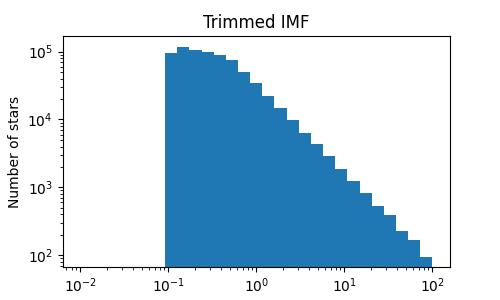

In [6]:
#trimming the IMF to exclude anything less than 1 solar mass
#BaSTI isochrones do not include stars lower than 1 solar mass

%matplotlib widget
plt.clf()
plt.close('all') 
#-----------------------------------
#sort by ascending mass
sortedmasses = np.sort(masses)
print(sortedmasses)
print("sample initial mass = ", sortedmasses.sum())
#cut off masses less than 1 Msun
cutmasses = sortedmasses[sortedmasses >= 0.1]
print("real initial mass = ", cutmasses.sum())
print("======================================")
print("sample point count = ", len(sortedmasses))
print("real point count = ", len(cutmasses))

imf_points = pd.DataFrame()
imf_points['Initial Mass'] = cutmasses
display(imf_points)

#histogram of trimmed IMF
plt.figure('IMF', figsize=(5,3))
bins = np.logspace(np.log10(0.01), np.log10(100), 30)
plt.hist(imf_points['Initial Mass'], bins=bins)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mass (Msun)')
plt.ylabel('Number of stars')
plt.title('Trimmed IMF')

#### Linear Interpolation using BaSTI Isochrones

In [7]:
filters = combined_imp_isoc.columns.to_numpy()[6:-1]

#----------------isochrone--------insert imf
def interpolator(refdata_subset, newdata):
    #uses the "refdata_subset" as a reference for "newdata" to be interpolated
    #newdata should be the initial mass function points, and refdata should be the BaSTI isochrones
    #...with information about the final mass and the filter magnitudes
    #
    #
    minmass = refdata_subset['M/Mo(ini)'].min()
    maxmass = refdata_subset['M/Mo(ini)'].max()
    newdata = newdata.loc[(newdata['Initial Mass'] < maxmass) & (newdata['Initial Mass'] > minmass)].copy()
    #np.interp(x_new, x_data, y_data)
    #interpolate the final masses
    finalmasses_new = np.interp(newdata['Initial Mass'].to_numpy(), refdata_subset['M/Mo(ini)'].to_numpy(), refdata_subset['M/Mo(fin)'].to_numpy())
    newdata['Final Mass'] = finalmasses_new

    #filters
    for f in filters:
        #interpolate each filter magnitude pt and add to dataframe
        filters_new = np.interp(newdata['Initial Mass'].to_numpy(), refdata_subset['M/Mo(ini)'].to_numpy(), refdata_subset[f].to_numpy())
        newdata[f] = filters_new

    return newdata

#-----------------------------
iterations = []

for (age, mh), isochrone_subset in combined_imp_isoc.groupby(['Age (Myr)','[M/H]']):
    #send the imf to be interpolated by the isochrones as its reference
    out = interpolator(isochrone_subset, imf_points)
    #attach age and metallicity
    out['Age (Myr)'] = age
    out['[M/H]'] = mh
    #add each to 'iterations'
    iterations.append(out)

isochrone_full = pd.concat(iterations, ignore_index=True)
display(isochrone_full)


,Initial Mass,Final Mass,F070W,F090W,F115W,F150W,F200W,F277W,F356W,F444W,...,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M,Age (Myr),[M/H]
0,0.100000,0.100000,11.599797,10.728998,10.098099,9.510799,9.332998,9.089699,8.816299,8.746799,...,9.197098,9.001899,8.853399,8.787499,8.726399,8.729399,8.792500,8.755499,2000.0,-1.9
1,0.100002,0.100002,11.599787,10.728994,10.098095,9.510794,9.332993,9.089695,8.816296,8.746797,...,9.197094,9.001896,8.853396,8.787496,8.726396,8.729396,8.792498,8.755498,2000.0,-1.9
2,0.100002,0.100002,11.599787,10.728994,10.098095,9.510794,9.332993,9.089695,8.816296,8.746797,...,9.197094,9.001896,8.853396,8.787496,8.726396,8.729396,8.792498,8.755498,2000.0,-1.9
3,0.100002,0.100002,11.599786,10.728993,10.098095,9.510794,9.332993,9.089695,8.816296,8.746797,...,9.197094,9.001895,8.853396,8.787496,8.726396,8.729396,8.792498,8.755498,2000.0,-1.9
4,0.100002,0.100002,11.599785,10.728993,10.098094,9.510793,9.332992,9.089694,8.816296,8.746796,...,9.197093,9.001895,8.853396,8.787496,8.726396,8.729396,8.792498,8.755497,2000.0,-1.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18111160,1.107008,0.952163,-1.318949,-2.113753,-2.746749,-3.504707,-3.930412,-3.902274,-4.043334,-3.919158,...,-3.769336,-4.002227,-4.038434,-4.046918,-4.022458,-3.949751,-3.772943,-3.806012,10000.0,0.3
18111161,1.107019,0.951748,-1.366628,-2.187902,-2.830054,-3.595360,-4.027856,-3.998446,-4.142876,-4.015646,...,-3.864099,-4.099656,-4.137739,-4.146776,-4.119183,-4.044126,-3.869583,-3.903456,10000.0,0.3
18111162,1.107042,0.950585,-1.489385,-2.367225,-3.029968,-3.813347,-4.262229,-4.229699,-4.382024,-4.247399,...,-4.091737,-4.334261,-4.376491,-4.386456,-4.351632,-4.270872,-4.101499,-4.137396,10000.0,0.3
18111163,1.107048,0.950257,-1.521570,-2.412111,-3.079693,-3.867574,-4.320244,-4.286970,-4.441256,-4.304670,...,-4.147941,-4.392463,-4.435637,-4.445774,-4.409170,-4.326941,-4.158852,-4.195307,10000.0,0.3


#### "Summing" Filter Magnitudes

In [8]:
def magnitudesum(dataframe, filtername):
    #converts each individual magnitude into a luminosity,
    #then sums up all the luminosity points
    #multiplies the total luminosity by the scaling factor (M propto L)
    #then converts back into magnitudes
    magsinfilter = dataframe[filtername].to_numpy()
    magsintolums = 10**(-magsinfilter/2.5)
    totallums = magsintolums.sum()
    rescaledtotallums = totallums*scalingfactor
    totalmags = -2.5*np.log10(rescaledtotallums)
    #print(totallums)
    return totalmags

#-----------------------------
masses_sums_list = []
filtermags_sums_list = []

filternames = isochrone_full.columns.to_numpy()[2:-2]
#print(filternames)

#loop isolates each isochrone (sets of points where age and metallicity are the same)
#Then sends an individual isochrone to the magnitude sum function to be "summed"
#appends to list of the summed magnitudes
for (age, mhratio), single_isoc in isochrone_full.groupby(['Age (Myr)', '[M/H]']):

    #print(group)
    #Summing initial and final masses
    totalmassinitial = single_isoc['Initial Mass'].sum()*scalingfactor
    totalmassfinal = single_isoc['Final Mass'].sum()*scalingfactor
    totalmassloss = totalmassinitial-totalmassfinal
    
    masses_sums_list.append({
        "Total Mass (ini)": totalmassinitial,
        "Total Mass (fin)": totalmassfinal,
        "Total Mass Loss": totalmassloss
    })

    #grab only filter columns of the dataframe
    filter_values = single_isoc[filternames]
    row = {'Age (Myr)': age, '[M/H]': mhratio}
    
    #summing up the magnitudes
    for filtername in filternames:
        #run through magnitude sums function
        row[filtername] = magnitudesum(filter_values, filtername)
    #print(row)

    filtermags_sums_list.append(row)

masses_sums = pd.DataFrame(masses_sums_list)
filtermags_sums = pd.DataFrame(filtermags_sums_list)

allsums = pd.concat([masses_sums, filtermags_sums], axis=1)
allsums = allsums.loc[:, allsums.columns.notna() & (allsums.columns != "")] #remove nan and empty values

allsums.sort_values(by=['Age (Myr)', '[M/H]'], ascending=[True, True])

display(allsums)

,Total Mass (ini),Total Mass (fin),Total Mass Loss,Age (Myr),[M/H],F070W,F090W,F115W,F150W,F200W,...,F182M,F210M,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M
0,2.399105e+07,2.398201e+07,9038.144510,2000.0,-1.90,-14.792900,-15.111678,-15.388026,-15.799701,-15.971261,...,-15.967101,-15.977163,-15.996564,-16.016830,-16.023385,-16.029644,-16.041206,-16.037538,-16.030354,-16.030864
1,2.615897e+07,2.614805e+07,10915.967541,2000.0,0.15,-14.461867,-14.926157,-15.352871,-15.927089,-16.235976,...,-16.224531,-16.248595,-16.140734,-16.291308,-16.317345,-16.326985,-16.319908,-16.272245,-16.147739,-16.169349
2,2.638351e+07,2.637362e+07,9885.715786,2000.0,0.30,-14.385112,-14.867673,-15.306942,-15.882363,-16.202282,...,-16.188978,-16.216415,-16.100493,-16.261013,-16.290300,-16.300171,-16.287813,-16.234925,-16.109310,-16.132904
3,2.270403e+07,2.269453e+07,9492.071735,3000.0,-1.90,-14.596132,-14.949564,-15.251757,-15.695239,-15.880803,...,-15.876004,-15.887406,-15.906456,-15.930095,-15.937290,-15.943998,-15.956077,-15.951049,-15.938506,-15.940229
4,2.490626e+07,2.489556e+07,10700.146215,3000.0,0.15,-14.082013,-14.595481,-15.054684,-15.659789,-15.995917,...,-15.982535,-16.010216,-15.890574,-16.055361,-16.086851,-16.098467,-16.089064,-16.039050,-15.918682,-15.942117
5,2.511266e+07,2.510256e+07,10106.852057,3000.0,0.30,-13.993263,-14.571621,-15.077138,-15.691179,-16.068510,...,-16.049889,-16.086748,-15.932761,-16.140409,-16.184891,-16.198404,-16.194334,-16.154572,-16.063653,-16.085098
6,2.180167e+07,2.179257e+07,9098.778690,4000.0,-1.90,-14.318607,-14.677266,-14.982270,-15.427459,-15.613694,...,-15.608574,-15.620617,-15.639728,-15.664488,-15.672180,-15.679173,-15.691565,-15.686299,-15.672613,-15.674622
7,2.406389e+07,2.405364e+07,10250.526399,4000.0,0.15,-13.846837,-14.398442,-14.881677,-15.507397,-15.863379,...,-15.848468,-15.878968,-15.749128,-15.926017,-15.961884,-15.974908,-15.964713,-15.914261,-15.798926,-15.823240
8,2.428640e+07,2.427662e+07,9782.599169,4000.0,0.30,-13.778223,-14.373280,-14.891106,-15.519656,-15.898288,...,-15.879921,-15.916642,-15.762289,-15.964987,-16.012147,-16.026652,-16.018789,-15.972638,-15.869979,-15.893622
9,2.109819e+07,2.108885e+07,9342.522885,5000.0,-1.90,-14.206154,-14.580089,-14.895081,-15.351781,-15.541981,...,-15.536704,-15.549102,-15.568699,-15.594006,-15.601946,-15.609107,-15.621715,-15.616265,-15.602010,-15.604205


#### K corrections
K corrections from Reina-Campos and Harris: https://arxiv.org/pdf/2310.02307 \
\
$M_{absolute,restframe} = m_{observed, in filter} - 5log_{10}(\frac{distance}{10pc}) - K_{correction}$
\
$M_{absolute,restframe} = M_{absolute,infilter} - K_{correction}$

In [9]:
"""
hoping to use K corrections from zenodo to accomodate different lookback times/redshifts and more filters (and metallicities)

for now, using K corrections for solar metallicity and mean age of 4Gyr or 8Gyr
mentioned in: PEARLS Globular Clusters and Ultra-Compact Dwarfs in the El Gordo Galaxies at z=0.87

- 4Gyr correction is used for ages 2-6
- 8Gyr correction is used for ages 7-10
"""

#in future, will import K-corrections here

Kcorrections = pd.DataFrame()

Kcorrections['Age (Myr)'] = [4000, 8000]
Kcorrections['F150W'] = [-0.05, -0.16]
Kcorrections['F200W'] = [-0.46, -0.41]

display(Kcorrections)

,Age (Myr),F150W,F200W
0,4000,-0.05,-0.46
1,8000,-0.16,-0.41


In [10]:
#applying Kcorrections to sums

#only the params listed below
filts_to_correct = ['F150W', 'F200W']
ages_to_correct = np.arange(2000, 11000, 1000)
mlictys_to_correct = [-1.90, 0.15, 0.30]

#extracting a smaller df with only listed filters and ages
correcting_sums = allsums.loc[(allsums['Age (Myr)'].isin(ages_to_correct)) & (allsums['[M/H]'].isin(mlictys_to_correct)),['Age (Myr)', '[M/H]'] + filts_to_correct]
#display(correcting_sums)

for filt in filts_to_correct:
    Kcorr_4000 = Kcorrections.loc[Kcorrections['Age (Myr)'] == 4000, filt].iloc[0]
    Kcorr_8000 = Kcorrections.loc[Kcorrections['Age (Myr)'] == 8000, filt].iloc[0]
    
    for age in ages_to_correct[:5]:
        correcting_sums.loc[correcting_sums['Age (Myr)'] == age, filt] -= Kcorr_4000
    for age in ages_to_correct[5:]:
        correcting_sums.loc[correcting_sums['Age (Myr)'] == age, filt] -= Kcorr_8000

display(correcting_sums)

,Age (Myr),[M/H],F150W,F200W
0,2000.0,-1.90,-15.749701,-15.511261
1,2000.0,0.15,-15.877089,-15.775976
2,2000.0,0.30,-15.832363,-15.742282
3,3000.0,-1.90,-15.645239,-15.420803
4,3000.0,0.15,-15.609789,-15.535917
5,3000.0,0.30,-15.641179,-15.608510
6,4000.0,-1.90,-15.377459,-15.153694
7,4000.0,0.15,-15.457397,-15.403379
8,4000.0,0.30,-15.469656,-15.438288
9,5000.0,-1.90,-15.301781,-15.081981


#### AB corrections
$M_{AB} = M_{absolute,Vega-Sirius} + conv_{Vega, AB}$\
$conv_{Vega,AB} = zp_{AB} - zp_{Vega-Sirius} - 2.5log_{10}(PHOTMJSR)$

In [11]:
#m_AB=m_Vega-sirius + conversion_factor.

ABcorrections = pd.read_csv('NRC_ZPs_1126pmap.txt', sep='|', header=4)
print(ABcorrections.columns[1:-1])

PHOTMJSR = ABcorrections[' PHOTMJSR ']
pupil_filter = ABcorrections[' pupil+filter ']
zp_vega_sirius = ABcorrections[' zp_vega-sirius ']
zp_AB = ABcorrections[' zp_AB ']
conv_Vega_AB = (zp_AB-zp_vega_sirius-2.5*np.log10(PHOTMJSR))
"""
for i in range(len(filter)):
    print(f'{pupil_filter[i]}, {conv_Vega_AB[i]:.3f}')
"""
convsns = pd.DataFrame({'ABconversion': conv_Vega_AB})
ABconversions = pd.concat([pupil_filter, convsns], axis=1)
#avg over where the filternames are the same
meanABconversions = ABconversions.groupby(' pupil+filter ', as_index=False)['ABconversion'].mean()
meanABconversions[' pupil+filter '] = (meanABconversions[' pupil+filter '].str.strip()) #remove spaces
display(meanABconversions)

Index([' pupil+filter ', '      sca ', ' PHOTMJSR ', ' zp_vega ', '  vega_Jy ',
       ' zp_vega-sirius ', ' vega-sirius_Jy ', ' zp_AB ', ' mean_pix_sr '],
      dtype='object')


,pupil+filter,ABconversion
0,CLEAR+F070W,0.233346
1,CLEAR+F090W,0.485512
2,CLEAR+F115W,0.765371
3,CLEAR+F140M,1.099317
4,CLEAR+F150W,1.205526
5,CLEAR+F182M,1.569256
6,CLEAR+F187N,1.637142
7,CLEAR+F200W,1.687174
8,CLEAR+F210M,1.791472
9,CLEAR+F212N,1.813027


In [12]:
#for now, correcting just F150W and F200W
filtnames = []
for filtname in filts_to_correct:
    filtlabel = "CLEAR+"+filtname
    filtnames.append(filtlabel)

print(filtnames)

#new table to prevent redunant addition
restframe_sums = correcting_sums.copy()

for filt,filtc in zip(filtnames,filts_to_correct): #parallel iteration
    ABcorr = meanABconversions.loc[meanABconversions[' pupil+filter '] == filt, 'ABconversion'].iloc[0]
    restframe_sums[filtc] += ABcorr

display(restframe_sums)

['CLEAR+F150W', 'CLEAR+F200W']


,Age (Myr),[M/H],F150W,F200W
0,2000.0,-1.90,-14.544175,-13.824087
1,2000.0,0.15,-14.671564,-14.088802
2,2000.0,0.30,-14.626838,-14.055108
3,3000.0,-1.90,-14.439713,-13.733629
4,3000.0,0.15,-14.404263,-13.848743
5,3000.0,0.30,-14.435654,-13.921336
6,4000.0,-1.90,-14.171934,-13.466519
7,4000.0,0.15,-14.251871,-13.716205
8,4000.0,0.30,-14.264131,-13.751114
9,5000.0,-1.90,-14.096255,-13.394807


#### Plotting CMD

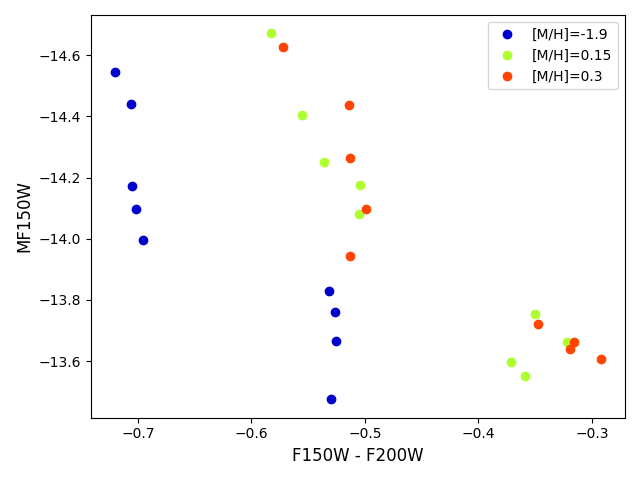

In [13]:
plt.clf()
plt.close('all') 
%matplotlib widget
#---------------------------

g = restframe_sums
#Now plotting anything we want

plt.figure("F150W")
#plt.title(m_h+" "+redshift+" "+mass)
plt.xlabel("F150W - F200W", fontsize=12)
plt.ylabel("MF150W", fontsize=12)

colors = ["mediumblue", "greenyellow", "orangered"]

for mlicty,color in zip(mlictys_to_correct,colors):
    plt.plot(g.loc[g["[M/H]"] == mlicty, "F150W"] - g.loc[g["[M/H]"] == mlicty, "F200W"], g.loc[g["[M/H]"] == mlicty, "F150W"], "o", label=f"[M/H]={mlicty}", color=color)

plt.legend()
plt.tight_layout()
ax = plt.gca() # Get current axes
ax.invert_yaxis()